<a href="https://colab.research.google.com/github/Heena667/Demo-/blob/main/finalPhageMind.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip install torch-geometric higher -q
!unzip -qo "/content/drive/MyDrive/data_all.zip" -d "/content/"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install torch-geometric -q
import os, torch
os.makedirs('/content/PhageMind_repo/src', exist_ok=True)
!unzip -qo "/content/drive/MyDrive/data_all.zip" -d "/content/"
print(os.listdir("/content"))

['.config', 'Alteromonas', 'SplitDir', 'PhageMind_repo', 'drive', 'Vibrio', 'Klebsiella', 'Escherichia', 'MAMLDir', 'InputDir', 'sample_data']


In [ ]:
split_dir = '/content/SplitDir'
print(os.listdir(split_dir))

['Alteromonas_test_edges.csv', 'Alteromonas_train_edges.csv', 'Escherichia_valid_edges.csv', 'Klebsiella_2_test_edges.csv', 'Klebsiella_2_valid_features.csv', 'Klebsiella_1_train_features.csv', 'Alteromonas_valid_features.csv', 'Klebsiella_2_train_features.csv', 'Alteromonas_test_features.csv', 'Alteromonas_valid_edges.csv', 'Klebsiella_2_test_features.csv', 'Vibrio_valid_edges.csv', 'Klebsiella_1_test_features.csv', 'Klebsiella_2_train_edges.csv', 'Vibrio_train_edges.csv', 'Klebsiella_1_test_edges.csv', 'Klebsiella_1_train_edges.csv', 'Vibrio_test_features.csv', 'Escherichia_train_features.csv', 'Klebsiella_1_valid_features.csv', 'Vibrio_test_edges.csv', 'Escherichia_test_edges.csv', 'Alteromonas_train_features.csv', 'Klebsiella_1_valid_edges.csv', 'Klebsiella_2_valid_edges.csv', 'Vibrio_train_features.csv', 'Escherichia_valid_features.csv', 'Escherichia_test_features.csv', 'Vibrio_valid_features.csv', 'Escherichia_train_edges.csv']


In [ ]:
import pandas as pd
for genus in ['Alteromonas', 'Escherichia', 'Vibrio']:
    print(f"--- {genus} edges ---")
    print(pd.read_csv(f"{split_dir}/{genus}_train_edges.csv").head())
    print(f"--- {genus} features ---")
    print(pd.read_csv(f"{split_dir}/{genus}_train_features.csv").head())

print("--- Klebsiella_1 edges ---")
print(pd.read_csv(f"{split_dir}/Klebsiella_1_train_edges.csv").head())
print("--- Klebsiella_2 edges ---")
print(pd.read_csv(f"{split_dir}/Klebsiella_2_train_edges.csv").head())

--- Alteromonas edges ---
    28  133  0.0
0  109  133  0.0
1   86  133  1.0
2  110  133  0.0
3   51  133  0.0
4   25  133  1.0
--- Alteromonas features ---
   0.2989992  0.29429528  0.20110077  0.20560476  0.40670553  0.037536178  \
0   0.297545    0.273695    0.197992    0.230768    0.428760     0.024064   
1   0.293715    0.309211    0.216944    0.180130    0.397074     0.042324   
2   0.284777    0.304560    0.221665    0.188997    0.410662     0.043053   
3   0.294334    0.301604    0.181787    0.222275    0.404062     0.037201   
4   0.290078    0.285353    0.220173    0.204396    0.424569     0.039636   

   0.027780414  0.023856156  0.022140775  0.01167417  ...  0.13333334  \
0     0.012359     0.024591     0.019303    0.012711  ...    0.131944   
1     0.050074     0.018806     0.018761    0.010948  ...    0.139752   
2     0.041910     0.018736     0.024196    0.013445  ...    0.157738   
3     0.021902     0.025386     0.013455    0.010600  ...    0.134211   
4     0.038315 

In [ ]:
for genus in ['Alteromonas', 'Escherichia', 'Vibrio', 'Klebsiella_1', 'Klebsiella_2']:
    e = pd.read_csv(f"{split_dir}/{genus}_train_edges.csv", header=None)
    f = pd.read_csv(f"{split_dir}/{genus}_train_features.csv", header=None)
    print(f"=== {genus} ===")
    print("edges shape:", e.shape)
    print("edges label value_counts:", e[2].value_counts().to_dict())
    print("col0 (min,max,nunique):", e[0].min(), e[0].max(), e[0].nunique())
    print("col1 (min,max,nunique):", e[1].min(), e[1].max(), e[1].nunique())
    print("do col0/col1 id ranges overlap?:", set(e[0].unique()) & set(e[1].unique()))
    print("features shape:", f.shape)
    print()


=== Alteromonas ===
edges shape: (1572, 3)
edges label value_counts: {0.0: 854, 1.0: 718}
col0 (min,max,nunique): 0 136 137
col1 (min,max,nunique): 0 136 137
do col0/col1 id ranges overlap?: {np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(55), np.int64(56), np.int64(57), np.int

In [ ]:
print(os.listdir('/content/InputDir'))
print(os.listdir('/content/MAMLDir'))
print(os.listdir('/content/Alteromonas'))  # the raw per-genus folder, not SplitDir

['phageVibrio.csv', 'phageKlebsiella_2.csv', 'bactKlebsiella_2.csv', 'phageAlteromonas.csv', 'bactEscherichia.csv', 'edgeAlteromonas.csv', 'bactKlebsiella_1.csv', 'edgeVibrio.csv', 'bactAlteromonas.csv', 'edgeEscherichia.csv', 'phageKlebsiella_1.csv', 'edgeKlebsiella_1.csv', 'edgeKlebsiella_2.csv', 'phageEscherichia.csv', 'bactVibrio.csv']
['Escherichia_best_model.pth', 'Klebsiella_best_model.pth', 'Alteromonas_best_model.pth', 'Vibrio_best_model.pth', 'MAML_best_model.pth']
['bacteria', 'interaction', 'phages']


In [ ]:
e = pd.read_csv(f"{split_dir}/Alteromonas_train_edges.csv", header=None)

for split in range(1, 137):
    bad = ((e[0] < split) & (e[1] < split)).sum() + ((e[0] >= split) & (e[1] >= split)).sum()
    if bad == 0:
        print("candidate split:", split)

candidate split: 131


In [ ]:
for genus in ['Alteromonas', 'Escherichia', 'Vibrio', 'Klebsiella_1', 'Klebsiella_2']:
    bfile = f'/content/InputDir/bact{genus}.csv'
    pfile = f'/content/InputDir/phage{genus}.csv'
    b = pd.read_csv(bfile)
    p = pd.read_csv(pfile)
    print(genus, "bacteria rows:", b.shape, "phage rows:", p.shape)
    print(genus, "bacteria file columns:", list(b.columns)[:5])
    print(genus, "phage file columns:", list(p.columns)[:5])

Alteromonas bacteria rows: (174, 1765) phage rows: (8, 757)
Alteromonas bacteria file columns: ['190', '0.2571007643065646', '0.2578081950620179', '0.24173048943610415', '0.24303503594991258']
Alteromonas phage file columns: ['P6062', '0.2412346030088095', '0.21448357789525568', '0.26460140397032716', '0.27968041512560765']
Escherichia bacteria rows: (402, 1765) phage rows: (96, 757)
Escherichia bacteria file columns: ['001-023', '0.24673755967420227', '0.24450124610684898', '0.25320566607575445', '0.2555555281431943']
Escherichia phage file columns: ['409_P1', '0.26765284422022245', '0.2383026831081803', '0.22661824533177216', '0.2674262273398251']
Vibrio bacteria rows: (28, 1765) phage rows: (21, 757)
Vibrio bacteria file columns: ['H10', '0.27798965781110757', '0.27699148873498436', '0.2249232248632539', '0.2200956285906542']
Vibrio phage file columns: ['17749XS2312', '0.31436997231773395', '0.2608409266584404', '0.19019620548810978', '0.23459289553571577']
Klebsiella_1 bacteria row

In [ ]:

ckpt = torch.load('/content/MAMLDir/MAML_best_model.pth', map_location='cpu')
print(type(ckpt))
if isinstance(ckpt, dict):
    print(list(ckpt.keys())[:20])

    for k, v in ckpt.items():
        if hasattr(v, 'shape'):
            print(k, tuple(v.shape))
        else:
            print(k, type(v))

<class 'collections.OrderedDict'>
['hete0.weight', 'hete0.bias', 'hete1.weight', 'hete1.bias', 'conv1.bias', 'conv1.lin.weight', 'conv2.bias', 'conv2.lin.weight', 'lin0.weight', 'lin0.bias', 'lin1.weight', 'lin1.bias', 'adapter0.0.weight', 'adapter0.0.bias', 'adapter0.2.weight', 'adapter0.2.bias', 'adapter1.0.weight', 'adapter1.0.bias', 'adapter1.2.weight', 'adapter1.2.bias']
hete0.weight (64, 756)
hete0.bias (64,)
hete1.weight (64, 1764)
hete1.bias (64,)
conv1.bias (32,)
conv1.lin.weight (32, 64)
conv2.bias (16,)
conv2.lin.weight (16, 32)
lin0.weight (8, 16)
lin0.bias (8,)
lin1.weight (1, 8)
lin1.bias (1,)
adapter0.0.weight (16, 64)
adapter0.0.bias (16,)
adapter0.2.weight (64, 16)
adapter0.2.bias (64,)
adapter1.0.weight (16, 64)
adapter1.0.bias (16,)
adapter1.2.weight (64, 16)
adapter1.2.bias (64,)


In [ ]:
import pandas as pd, numpy as np

feat = pd.read_csv(f"{split_dir}/Alteromonas_train_features.csv", header=None)
edges = pd.read_csv(f"{split_dir}/Alteromonas_train_edges.csv", header=None)

# from our earlier search: split=131 separates bacteria (<131) from phage (>=131) in this file's ID space
bact_rows = feat[feat.index < 131]
phage_rows = feat[feat.index >= 131]

print("bacteria row nonzero-cols mean:", (bact_rows != 0).mean(axis=1).mean())
print("phage row nonzero-cols mean:", (phage_rows != 0).mean(axis=1).mean())
print("phage rows, cols 756: check if tail (cols 756-1763) are all ~0")
print(phage_rows.iloc[:, 756:].abs().values.max())
print(phage_rows.iloc[:, 756:].abs().values.mean())

bacteria row nonzero-cols mean: 0.9492738571255475
phage row nonzero-cols mean: 0.9810090702947846
phage rows, cols 756: check if tail (cols 756-1763) are all ~0
999.0
999.0


In [ ]:
import pandas as pd

for split in ['train', 'valid', 'test']:
    e = pd.read_csv(f"{split_dir}/Escherichia_{split}_edges.csv", header=None)
    f = pd.read_csv(f"{split_dir}/Escherichia_{split}_features.csv", header=None)
    print(f"--- {split} ---")
    print("edges shape:", e.shape, "| max id seen:", max(e[0].max(), e[1].max()), "| features rows:", f.shape[0])

    # find local bacteria/phage boundary within this split only
    n = f.shape[0]
    for cand in range(1, n):
        bad = ((e[0] < cand) & (e[1] < cand)).sum() + ((e[0] >= cand) & (e[1] >= cand)).sum()
        if bad == 0:
            print("  candidate local boundary:", cand, " -> bact:", cand, " phage:", n - cand)

--- train ---
edges shape: (42620, 3) | max id seen: 373 | features rows: 374
  candidate local boundary: 302  -> bact: 302  phage: 72
--- valid ---
edges shape: (15376, 3) | max id seen: 435 | features rows: 500
--- test ---
edges shape: (18874, 3) | max id seen: 499 | features rows: 500


In [ ]:
import pandas as pd
import numpy as np

train_f = pd.read_csv(f"{split_dir}/Escherichia_train_features.csv", header=None).to_numpy()
test_f  = pd.read_csv(f"{split_dir}/Escherichia_test_features.csv", header=None).to_numpy()
valid_f = pd.read_csv(f"{split_dir}/Escherichia_valid_features.csv", header=None).to_numpy()

# 1) does train's id space look like a literal prefix of test's id space?
print("train[0] == test[0]?", np.allclose(train_f[0], test_f[0]))
print("train[1] == test[1]?", np.allclose(train_f[1], test_f[1]))
print("train[301] (last train bact) == test[301]?", np.allclose(train_f[301], test_f[301]))

# 2) does test == valid entirely (same global table, just different active edges)?
print("test_features == valid_features (whole table)?", np.array_equal(test_f, valid_f))

# 3) if (1) is false, search whether each train row appears SOMEWHERE in test (possibly reordered)
#    just check row 0 and row 302 (first phage row in train) as a spot-check
def find_match(row, table, tol=1e-6):
    diffs = np.abs(table - row).max(axis=1)
    idx = np.argmin(diffs)
    return idx, diffs[idx]

idx0, d0 = find_match(train_f[0], test_f)
idx302, d302 = find_match(train_f[302], test_f)
print("train bact row0 best match in test -> idx:", idx0, "diff:", d0)
print("train phage row302 best match in test -> idx:", idx302, "diff:", d302)

train[0] == test[0]? True
train[1] == test[1]? True
train[301] (last train bact) == test[301]? True
test_features == valid_features (whole table)? True
train bact row0 best match in test -> idx: 0 diff: 0.0
train phage row302 best match in test -> idx: 302 diff: 0.0


In [ ]:
import pandas as pd

for genus in ['Escherichia', 'Vibrio', 'Klebsiella_1', 'Klebsiella_2', 'Alteromonas']:
    e = pd.read_csv(f"{split_dir}/{genus}_test_edges.csv", header=None)
    f = pd.read_csv(f"{split_dir}/{genus}_test_features.csv", header=None)
    n = f.shape[0]
    found = []
    for cand in range(1, n):
        bad = ((e[0] < cand) & (e[1] < cand)).sum() + ((e[0] >= cand) & (e[1] >= cand)).sum()
        if bad == 0:
            found.append(cand)
    print(genus, "n_total:", n, "candidate global boundaries:", found)

Escherichia n_total: 500 candidate global boundaries: []
Vibrio n_total: 51 candidate global boundaries: []
Klebsiella_1 n_total: 121 candidate global boundaries: []
Klebsiella_2 n_total: 184 candidate global boundaries: []
Alteromonas n_total: 184 candidate global boundaries: []


In [ ]:
import pandas as pd
import numpy as np

for genus in ['Escherichia', 'Vibrio', 'Klebsiella_1', 'Klebsiella_2', 'Alteromonas']:
    f = pd.read_csv(f"{split_dir}/{genus}_test_features.csv", header=None).to_numpy()
    e = pd.read_csv(f"{split_dir}/{genus}_test_edges.csv", header=None)

    tail = f[:, 756:1764]
    is_phage = np.isclose(tail, 999.0).mean(axis=1) > 0.99   # True = phage row
    n_bact = (~is_phage).sum()
    n_phage = is_phage.sum()

    a = e[0].to_numpy()
    b = e[1].to_numpy()
    same_side = (is_phage[a] == is_phage[b]).sum()

    print(genus, "| n_total:", f.shape[0], "n_bact:", n_bact, "n_phage:", n_phage,
          "| same-side edges (should be 0):", same_side, "/ total edges:", len(a))

Escherichia | n_total: 500 n_bact: 500 n_phage: 0 | same-side edges (should be 0): 18874 / total edges: 18874
Vibrio | n_total: 51 n_bact: 51 n_phage: 0 | same-side edges (should be 0): 320 / total edges: 320
Klebsiella_1 | n_total: 121 n_bact: 121 n_phage: 0 | same-side edges (should be 0): 1808 / total edges: 1808
Klebsiella_2 | n_total: 184 n_bact: 184 n_phage: 0 | same-side edges (should be 0): 3096 / total edges: 3096
Alteromonas | n_total: 184 n_bact: 184 n_phage: 0 | same-side edges (should be 0): 1008 / total edges: 1008


In [ ]:
import pandas as pd
import numpy as np

f = pd.read_csv(f"{split_dir}/Escherichia_test_features.csv", header=None).to_numpy()
tail = f[:, 756:1764]

print("tail min/max/mean overall:", tail.min(), tail.max(), tail.mean())
print("per-row tail mean, first 10 rows:", tail[:10].mean(axis=1))
print("per-row tail mean, rows 370-380 (around train boundary):", tail[370:380].mean(axis=1))
print("per-row tail mean, last 10 rows:", tail[-10:].mean(axis=1))

# distribution of per-row tail means across ALL 500 rows, to see if there's a bimodal split
row_means = tail.mean(axis=1)
print("row_means describe:")
print(pd.Series(row_means).describe())
print("value_counts of rows with tail mean > 500:", (row_means > 500).sum())
print("value_counts of rows with tail mean < 1:", (row_means < 1).sum())

tail min/max/mean overall: -999.0 89.1875 -193.4419826008908
per-row tail mean, first 10 rows: [0.41698484 0.448201   0.44539459 0.45668783 0.46028532 0.46262805
 0.4205824  0.47137765 0.41258221 0.4768066 ]
per-row tail mean, rows 370-380 (around train boundary): [-9.99000000e+02 -9.99000000e+02 -9.99000000e+02 -9.99000000e+02
  4.61965672e-01  4.45579616e-01  4.39833994e-01  4.78061579e-01
  4.75902315e-01  4.60116426e-01]
per-row tail mean, last 10 rows: [-999. -999. -999. -999. -999. -999. -999. -999. -999. -999.]
row_means describe:
count    500.000000
mean    -193.441983
std      395.607848
min     -999.000000
25%        0.424029
50%        0.444108
75%        0.458645
max        0.551342
dtype: float64
value_counts of rows with tail mean > 500: 0
value_counts of rows with tail mean < 1: 500


In [ ]:
import os
for root, dirs, files in os.walk('/content/PhageMind_repo'):
    for fn in files:
        print(os.path.join(root, fn))

/content/PhageMind_repo/src/phagemind_model.py
/content/PhageMind_repo/src/phagemind_visualize.py
/content/PhageMind_repo/src/phagemind_data.py
/content/PhageMind_repo/src/phagemind_train_baseline.py
/content/PhageMind_repo/src/phagemind_maml.py
/content/PhageMind_repo/src/__pycache__/phagemind_train_baseline.cpython-312.pyc
/content/PhageMind_repo/src/__pycache__/phagemind_maml.cpython-312.pyc
/content/PhageMind_repo/src/__pycache__/phagemind_data.cpython-312.pyc
/content/PhageMind_repo/src/__pycache__/phagemind_model.cpython-312.pyc


In [ ]:
import pandas as pd
import numpy as np

for genus in ['Escherichia', 'Vibrio', 'Klebsiella_1', 'Klebsiella_2', 'Alteromonas']:
    f = pd.read_csv(f"{split_dir}/{genus}_test_features.csv", header=None).to_numpy()
    e = pd.read_csv(f"{split_dir}/{genus}_test_edges.csv", header=None)

    tail = f[:, 756:1764]
    is_phage = np.isclose(tail, -999.0).mean(axis=1) > 0.99   # corrected sign
    n_bact = (~is_phage).sum()
    n_phage = is_phage.sum()

    a = e[0].to_numpy()
    b = e[1].to_numpy()
    same_side = (is_phage[a] == is_phage[b]).sum()

    print(genus, "| n_total:", f.shape[0], "n_bact:", n_bact, "n_phage:", n_phage,
          "| same-side edges (should be 0):", same_side, "/ total:", len(a))

Escherichia | n_total: 500 n_bact: 403 n_phage: 97 | same-side edges (should be 0): 0 / total: 18874
Vibrio | n_total: 51 n_bact: 29 n_phage: 22 | same-side edges (should be 0): 0 / total: 320
Klebsiella_1 | n_total: 121 n_bact: 62 n_phage: 59 | same-side edges (should be 0): 0 / total: 1808
Klebsiella_2 | n_total: 184 n_bact: 138 n_phage: 46 | same-side edges (should be 0): 0 / total: 3096
Alteromonas | n_total: 184 n_bact: 175 n_phage: 9 | same-side edges (should be 0): 0 / total: 1008


In [ ]:
%%writefile /content/PhageMind_repo/src/phagemind_data.py
import numpy as np


PHAGE_FEAT_DIM = 756
BACT_FEAT_DIM = 1764
PHAGE_SENTINEL = -999.0


def classify_nodes(feat_1764):
    tail = feat_1764[:, PHAGE_FEAT_DIM:BACT_FEAT_DIM]
    return np.isclose(tail.mean(axis=1), PHAGE_SENTINEL, atol=1.0)


def load_split_table(split_dir, genus, split):
    feat_path = os.path.join(split_dir, f"{genus}_{split}_features.csv")
    edge_path = os.path.join(split_dir, f"{genus}_{split}_edges.csv")

    feat = pd.read_csv(feat_path, header=None).to_numpy(dtype=np.float32)
    is_phage = classify_nodes(feat)

    n_total = feat.shape[0]
    local_idx = np.zeros(n_total, dtype=np.int64)
    local_idx[~is_phage] = np.arange((~is_phage).sum())
    local_idx[is_phage] = np.arange(is_phage.sum())

    bact_feat = feat[~is_phage, :BACT_FEAT_DIM]
    phage_feat = feat[is_phage, :PHAGE_FEAT_DIM]

    e = pd.read_csv(edge_path, header=None)
    src = e.iloc[:, 0].to_numpy(dtype=np.int64)
    dst = e.iloc[:, 1].to_numpy(dtype=np.int64)
    label = e.iloc[:, 2].to_numpy(dtype=np.float32)

    assert np.all(is_phage[src] != is_phage[dst]), f"{genus}/{split}: found same-type edge"

    pos_mask = label > 0.5
    edges_pos_global = (src[pos_mask], dst[pos_mask])

    return {
        "bact_feat": torch.tensor(bact_feat),
        "phage_feat": torch.tensor(phage_feat),
        "is_phage": is_phage,
        "local_idx": local_idx,
        "n_bact": int((~is_phage).sum()),
        "n_phage": int(is_phage.sum()),
        "edges_all": (src, dst, label),
        "edges_pos_global": edges_pos_global,
    }


def _remap(raw_ids, is_phage, local_idx, n_bact):
    out = np.empty_like(raw_ids)
    phage_mask = is_phage[raw_ids]
    out[phage_mask] = n_bact + local_idx[raw_ids[phage_mask]]
    out[~phage_mask] = local_idx[raw_ids[~phage_mask]]
    return out


def build_pyg_edge_index(n_bact, is_phage, local_idx, pos_src, pos_dst, device="cpu"):
    src_u = _remap(pos_src, is_phage, local_idx, n_bact)
    dst_u = _remap(pos_dst, is_phage, local_idx, n_bact)
    ei = np.stack([np.concatenate([src_u, dst_u]), np.concatenate([dst_u, src_u])])
    return torch.tensor(ei, dtype=torch.long, device=device)


def build_pair_index(n_bact, is_phage, local_idx, src, dst, label, device="cpu"):
    a = torch.tensor(_remap(src, is_phage, local_idx, n_bact), dtype=torch.long, device=device)
    b = torch.tensor(_remap(dst, is_phage, local_idx, n_bact), dtype=torch.long, device=device)
    y = torch.tensor(label, dtype=torch.float32, device=device)
    return a, b, y


def load_genus_split(split_dir, genus, split, device="cpu"):
    d = load_split_table(split_dir, genus, split)
    edge_index = build_pyg_edge_index(
        d["n_bact"], d["is_phage"], d["local_idx"],
        d["edges_pos_global"][0], d["edges_pos_global"][1], device=device,
    )
    src, dst, label = d["edges_all"]
    pair_a, pair_b, pair_y = build_pair_index(
        d["n_bact"], d["is_phage"], d["local_idx"], src, dst, label, device=device
    )
    return {
        "bact_feat": d["bact_feat"].to(device),
        "phage_feat": d["phage_feat"].to(device),
        "n_bact": d["n_bact"],
        "n_phage": d["n_phage"],
        "edge_index": edge_index,
        "pair_a": pair_a,
        "pair_b": pair_b,
        "pair_y": pair_y,
    }

Overwriting /content/PhageMind_repo/src/phagemind_data.py


In [ ]:
%%writefile /content/PhageMind_repo/src/phagemind_model.py
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv


class Adapter(nn.Sequential):

    def __init__(self, dim=64, bottleneck=16):
        super().__init__(
            nn.Linear(dim, bottleneck),
            nn.ReLU(),
            nn.Linear(bottleneck, dim),
        )

    def forward(self, x):
        return x + super().forward(x)


class PhageMind(nn.Module):
    def __init__(self, bact_dim=1764, phage_dim=756, hidden=64, gcn1=32, gcn2=16, fc=8):
        super().__init__()
        self.hete1 = nn.Linear(bact_dim, hidden)   # bacteria
        self.hete0 = nn.Linear(phage_dim, hidden)  # phage

        self.adapter1 = Adapter(hidden, 16)  # bacteria
        self.adapter0 = Adapter(hidden, 16)  # phage

        self.conv1 = GCNConv(hidden, gcn1)
        self.conv2 = GCNConv(gcn1, gcn2)

        self.lin0 = nn.Linear(gcn2, fc)
        self.lin1 = nn.Linear(fc, 1)

    def encode_nodes(self, bact_feat, phage_feat):
        h_b = F.relu(self.hete1(bact_feat))
        h_p = F.relu(self.hete0(phage_feat))
        h_b = self.adapter1(h_b)
        h_p = self.adapter0(h_p)
        return torch.cat([h_b, h_p], dim=0)

    def propagate(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))
        return x

    def predict_pairs(self, node_emb, idx_a, idx_b):
        fused = node_emb[idx_a] + node_emb[idx_b]
        h = F.relu(self.lin0(fused))
        logit = self.lin1(h).squeeze(-1)
        return logit

    def forward(self, bact_feat, phage_feat, edge_index, idx_a, idx_b):
        x0 = self.encode_nodes(bact_feat, phage_feat)
        x = self.propagate(x0, edge_index)
        return self.predict_pairs(x, idx_a, idx_b)


def sanity_check_against_checkpoint(ckpt_path, data_dict, device="cpu"):
    model = PhageMind().to(device)
    ckpt = torch.load(ckpt_path, map_location=device)
    missing, unexpected = model.load_state_dict(ckpt, strict=True)
    print("load_state_dict OK. missing:", missing, "unexpected:", unexpected)

    model.eval()
    with torch.no_grad():
        logits = model(
            data_dict["bact_feat"], data_dict["phage_feat"],
            data_dict["edge_index"], data_dict["pair_a"], data_dict["pair_b"],
        )
        probs = torch.sigmoid(logits)
    print("logits stats: min", logits.min().item(), "max", logits.max().item(),
          "any nan:", torch.isnan(logits).any().item())
    print("probs range:", probs.min().item(), probs.max().item())
    return model, probs

Overwriting /content/PhageMind_repo/src/phagemind_model.py


In [ ]:
%%writefile /content/PhageMind_repo/src/phagemind_train_baseline.py

import copy
import torch.nn as nn
from sklearn.metrics import roc_auc_score
from phagemind_model import PhageMind


class PhageMindMLP(PhageMind):
    """Same encoders/adapters/head as PhageMind, but skips GCN propagation (Sec 3.1 MLP baseline)."""
    def forward(self, bact_feat, phage_feat, edge_index, idx_a, idx_b):
        x0 = self.encode_nodes(bact_feat, phage_feat)
        return self.predict_pairs(x0, idx_a, idx_b)


def make_masked_edge_index(full_pos_src, full_pos_dst, n_bact, is_phage, local_idx, mask_rate, device):
    n = full_pos_src.shape[0]
    if n == 0:
        return torch.zeros((2, 0), dtype=torch.long, device=device)
    keep = torch.rand(n) > mask_rate
    ks, kd = full_pos_src[keep.numpy()], full_pos_dst[keep.numpy()]
    from phagemind_data import _remap
    src_u = _remap(ks, is_phage, local_idx, n_bact)
    dst_u = _remap(kd, is_phage, local_idx, n_bact)
    ei = np.stack([np.concatenate([src_u, dst_u]), np.concatenate([dst_u, src_u])])
    return torch.tensor(ei, dtype=torch.long, device=device)


def train_single_genus_loop(model, split_dir, genus, device="cpu",
                             epochs=200, lr=1e-3, weight_decay=1e-5,
                             edge_mask_rate=0.7, use_masking=True, verbose=True):
    from phagemind_data import load_split_table, build_pyg_edge_index, build_pair_index

    train_raw = load_split_table(split_dir, genus, "train")
    valid_raw = load_split_table(split_dir, genus, "valid")
    test_raw = load_split_table(split_dir, genus, "test")

    def to_device_pairs(raw):
        src, dst, label = raw["edges_all"]
        a, b, y = build_pair_index(raw["n_bact"], raw["is_phage"], raw["local_idx"], src, dst, label, device=device)
        return a, b, y

    train_bact = train_raw["bact_feat"].to(device)
    train_phage = train_raw["phage_feat"].to(device)
    train_a, train_b, train_y = to_device_pairs(train_raw)
    train_pos_src, train_pos_dst = train_raw["edges_pos_global"]

    valid_bact = valid_raw["bact_feat"].to(device)
    valid_phage = valid_raw["phage_feat"].to(device)
    valid_a, valid_b, valid_y = to_device_pairs(valid_raw)
    valid_edge_index = build_pyg_edge_index(
        valid_raw["n_bact"], valid_raw["is_phage"], valid_raw["local_idx"],
        *valid_raw["edges_pos_global"], device=device,
    )

    test_bact = test_raw["bact_feat"].to(device)
    test_phage = test_raw["phage_feat"].to(device)
    test_a, test_b, test_y = to_device_pairs(test_raw)
    test_edge_index = build_pyg_edge_index(
        test_raw["n_bact"], test_raw["is_phage"], test_raw["local_idx"],
        *test_raw["edges_pos_global"], device=device,
    )

    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()

    best_valid_auc = -1.0
    best_state = None
    history = {"train_loss": [], "valid_auc": [], "test_auc": []}

    for epoch in range(epochs):
        model.train()
        if use_masking:
            edge_index = make_masked_edge_index(
                train_pos_src, train_pos_dst, train_raw["n_bact"],
                train_raw["is_phage"], train_raw["local_idx"], edge_mask_rate, device
            )
        else:
            edge_index = build_pyg_edge_index(
                train_raw["n_bact"], train_raw["is_phage"], train_raw["local_idx"],
                train_pos_src, train_pos_dst, device=device,
            )

        opt.zero_grad()
        logits = model(train_bact, train_phage, edge_index, train_a, train_b)
        loss = loss_fn(logits, train_y)
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            v_logits = model(valid_bact, valid_phage, valid_edge_index, valid_a, valid_b)
            v_auc = roc_auc_score(valid_y.cpu().numpy(), torch.sigmoid(v_logits).cpu().numpy())
            t_logits = model(test_bact, test_phage, test_edge_index, test_a, test_b)
            t_auc = roc_auc_score(test_y.cpu().numpy(), torch.sigmoid(t_logits).cpu().numpy())

        history["train_loss"].append(loss.item())
        history["valid_auc"].append(v_auc)
        history["test_auc"].append(t_auc)

        if v_auc > best_valid_auc:
            best_valid_auc = v_auc
            best_state = copy.deepcopy(model.state_dict())

        if verbose and (epoch % 20 == 0 or epoch == epochs - 1):
            print(f"[{genus}] epoch {epoch:3d} | loss {loss.item():.4f} | valid AUC {v_auc:.4f} | test AUC {t_auc:.4f}")

    model.load_state_dict(best_state)
    return model, history

Overwriting /content/PhageMind_repo/src/phagemind_train_baseline.py


In [ ]:
import sys
sys.path.append('/content/PhageMind_repo/src')
# remove cached modules so the next import re-reads the file from disk
for mod in ['phagemind_model', 'phagemind_data']:
    if mod in sys.modules:
        del sys.modules[mod]

from phagemind_data import load_genus_split
from phagemind_model import sanity_check_against_checkpoint

data = load_genus_split('/content/SplitDir', 'Escherichia', 'test', device='cpu')
model, probs = sanity_check_against_checkpoint('/content/MAMLDir/Escherichia_best_model.pth', data, device='cpu')

from sklearn.metrics import roc_auc_score
print("AUC:", roc_auc_score(data["pair_y"].cpu().numpy(), probs.cpu().numpy()))

load_state_dict OK. missing: [] unexpected: []
logits stats: min 0.11702561378479004 max 0.7216292023658752 any nan: False
probs range: 0.5292230844497681 0.6729657053947449
AUC: 0.8271081707004302


In [ ]:

import sys
sys.path.append('/content/PhageMind_repo/src')

from phagemind_data import load_genus_split
from phagemind_model import sanity_check_against_checkpoint

split_dir = '/content/SplitDir'
data = load_genus_split(split_dir, 'Escherichia', 'test', device='cpu')

print("n_bact:", data["n_bact"], "n_phage:", data["n_phage"])
print("edge_index shape:", data["edge_index"].shape)
print("pair_a/pair_b/pair_y shapes:", data["pair_a"].shape, data["pair_b"].shape, data["pair_y"].shape)

model, probs = sanity_check_against_checkpoint(
    '/content/MAMLDir/Escherichia_best_model.pth', data, device='cpu'
)

# quick AUC check using the pretrained checkpoint directly on test set
from sklearn.metrics import roc_auc_score
y_true = data["pair_y"].cpu().numpy()
y_score = probs.cpu().numpy()
print("AUC (pretrained checkpoint, zero-shot on test):", roc_auc_score(y_true, y_score))

n_bact: 403 n_phage: 97
edge_index shape: torch.Size([2, 7084])
pair_a/pair_b/pair_y shapes: torch.Size([18874]) torch.Size([18874]) torch.Size([18874])
load_state_dict OK. missing: [] unexpected: []
logits stats: min 0.11702561378479004 max 0.7216292023658752 any nan: False
probs range: 0.5292230844497681 0.6729657053947449
AUC (pretrained checkpoint, zero-shot on test): 0.8271081707004302


In [ ]:
%%writefile /content/PhageMind_repo/src/phagemind_train_baseline.py
import copy
import torch.nn as nn
from sklearn.metrics import roc_auc_score
from phagemind_model import PhageMind


class PhageMindMLP(PhageMind):
    """Same encoders/adapters/head as PhageMind, but skips GCN propagation (Sec 3.1 MLP baseline)."""
    def forward(self, bact_feat, phage_feat, edge_index, idx_a, idx_b):
        x0 = self.encode_nodes(bact_feat, phage_feat)
        return self.predict_pairs(x0, idx_a, idx_b)


def make_masked_edge_index(full_pos_src, full_pos_dst, n_bact, is_phage, local_idx, mask_rate, device):
    n = full_pos_src.shape[0]
    if n == 0:
        return torch.zeros((2, 0), dtype=torch.long, device=device)
    keep = torch.rand(n) > mask_rate
    ks, kd = full_pos_src[keep.numpy()], full_pos_dst[keep.numpy()]
    from phagemind_data import _remap
    src_u = _remap(ks, is_phage, local_idx, n_bact)
    dst_u = _remap(kd, is_phage, local_idx, n_bact)
    ei = np.stack([np.concatenate([src_u, dst_u]), np.concatenate([dst_u, src_u])])
    return torch.tensor(ei, dtype=torch.long, device=device)


def train_single_genus_loop(model, split_dir, genus, device="cpu",
                             epochs=200, lr=1e-3, weight_decay=1e-5,
                             edge_mask_rate=0.7, use_masking=True, verbose=True):
    from phagemind_data import load_split_table, build_pyg_edge_index, build_pair_index

    train_raw = load_split_table(split_dir, genus, "train")
    valid_raw = load_split_table(split_dir, genus, "valid")
    test_raw = load_split_table(split_dir, genus, "test")

    def to_device_pairs(raw):
        src, dst, label = raw["edges_all"]
        a, b, y = build_pair_index(raw["n_bact"], raw["is_phage"], raw["local_idx"], src, dst, label, device=device)
        return a, b, y

    train_bact = train_raw["bact_feat"].to(device)
    train_phage = train_raw["phage_feat"].to(device)
    train_a, train_b, train_y = to_device_pairs(train_raw)
    train_pos_src, train_pos_dst = train_raw["edges_pos_global"]

    valid_bact = valid_raw["bact_feat"].to(device)
    valid_phage = valid_raw["phage_feat"].to(device)
    valid_a, valid_b, valid_y = to_device_pairs(valid_raw)
    valid_edge_index = build_pyg_edge_index(
        valid_raw["n_bact"], valid_raw["is_phage"], valid_raw["local_idx"],
        *valid_raw["edges_pos_global"], device=device,
    )

    test_bact = test_raw["bact_feat"].to(device)
    test_phage = test_raw["phage_feat"].to(device)
    test_a, test_b, test_y = to_device_pairs(test_raw)
    test_edge_index = build_pyg_edge_index(
        test_raw["n_bact"], test_raw["is_phage"], test_raw["local_idx"],
        *test_raw["edges_pos_global"], device=device,
    )

    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()

    best_valid_auc = -1.0
    best_state = None
    history = {"train_loss": [], "valid_auc": [], "test_auc": []}

    for epoch in range(epochs):
        model.train()
        if use_masking:
            edge_index = make_masked_edge_index(
                train_pos_src, train_pos_dst, train_raw["n_bact"],
                train_raw["is_phage"], train_raw["local_idx"], edge_mask_rate, device
            )
        else:
            edge_index = build_pyg_edge_index(
                train_raw["n_bact"], train_raw["is_phage"], train_raw["local_idx"],
                train_pos_src, train_pos_dst, device=device,
            )

        opt.zero_grad()
        logits = model(train_bact, train_phage, edge_index, train_a, train_b)
        loss = loss_fn(logits, train_y)
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            v_logits = model(valid_bact, valid_phage, valid_edge_index, valid_a, valid_b)
            v_auc = roc_auc_score(valid_y.cpu().numpy(), torch.sigmoid(v_logits).cpu().numpy())
            t_logits = model(test_bact, test_phage, test_edge_index, test_a, test_b)
            t_auc = roc_auc_score(test_y.cpu().numpy(), torch.sigmoid(t_logits).cpu().numpy())

        history["train_loss"].append(loss.item())
        history["valid_auc"].append(v_auc)
        history["test_auc"].append(t_auc)

        if v_auc > best_valid_auc:
            best_valid_auc = v_auc
            best_state = copy.deepcopy(model.state_dict())

        if verbose and (epoch % 20 == 0 or epoch == epochs - 1):
            print(f"[{genus}] epoch {epoch:3d} | loss {loss.item():.4f} | valid AUC {v_auc:.4f} | test AUC {t_auc:.4f}")

    model.load_state_dict(best_state)
    return model, history

Overwriting /content/PhageMind_repo/src/phagemind_train_baseline.py


In [ ]:
!grep -A 15 "class PhageMindMLP" /content/PhageMind_repo/src/phagemind_train_baseline.py

class PhageMindMLP(PhageMind):
    """Same encoders/adapters/head as PhageMind, but skips GCN propagation (Sec 3.1 MLP baseline)."""
    def forward(self, bact_feat, phage_feat, edge_index, idx_a, idx_b):
        x0 = self.encode_nodes(bact_feat, phage_feat)
        return self.predict_pairs(x0, idx_a, idx_b)


def make_masked_edge_index(full_pos_src, full_pos_dst, n_bact, is_phage, local_idx, mask_rate, device):
    n = full_pos_src.shape[0]
    if n == 0:
        return torch.zeros((2, 0), dtype=torch.long, device=device)
    keep = torch.rand(n) > mask_rate
    ks, kd = full_pos_src[keep.numpy()], full_pos_dst[keep.numpy()]
    from phagemind_data import _remap
    src_u = _remap(ks, is_phage, local_idx, n_bact)
    dst_u = _remap(kd, is_phage, local_idx, n_bact)


In [ ]:
# STEP 1: write the file (single source of truth, run this and only this from now on)
%%writefile /content/PhageMind_repo/src/phagemind_train_baseline.py
import copy
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import roc_auc_score
from phagemind_model import PhageMind


class PhageMindMLP(PhageMind):
    def __init__(self, bact_dim=1764, phage_dim=756, hidden=64, gcn1=32, gcn2=16, fc=8):
        super().__init__(bact_dim, phage_dim, hidden, gcn1, gcn2, fc)
        self.lin0_mlp = nn.Linear(hidden, fc)
        self.lin1_mlp = nn.Linear(fc, 1)

    def forward(self, bact_feat, phage_feat, edge_index, idx_a, idx_b):
        x0 = self.encode_nodes(bact_feat, phage_feat)  # edge_index unused
        fused = x0[idx_a] + x0[idx_b]
        h = torch.relu(self.lin0_mlp(fused))
        return self.lin1_mlp(h).squeeze(-1)


def make_masked_edge_index(full_pos_src, full_pos_dst, n_bact, is_phage, local_idx, mask_rate, device):
    n = full_pos_src.shape[0]
    if n == 0:
        return torch.zeros((2, 0), dtype=torch.long, device=device)
    keep = torch.rand(n) > mask_rate
    ks, kd = full_pos_src[keep.numpy()], full_pos_dst[keep.numpy()]
    from phagemind_data import _remap
    src_u = _remap(ks, is_phage, local_idx, n_bact)
    dst_u = _remap(kd, is_phage, local_idx, n_bact)
    ei = np.stack([np.concatenate([src_u, dst_u]), np.concatenate([dst_u, src_u])])
    return torch.tensor(ei, dtype=torch.long, device=device)


def train_single_genus_loop(model, split_dir, genus, device="cpu",
                             epochs=200, lr=1e-3, weight_decay=1e-5,
                             edge_mask_rate=0.7, use_masking=True, verbose=True):
    from phagemind_data import load_split_table, build_pyg_edge_index, build_pair_index

    train_raw = load_split_table(split_dir, genus, "train")
    valid_raw = load_split_table(split_dir, genus, "valid")
    test_raw = load_split_table(split_dir, genus, "test")

    def to_device_pairs(raw):
        src, dst, label = raw["edges_all"]
        a, b, y = build_pair_index(raw["n_bact"], raw["is_phage"], raw["local_idx"], src, dst, label, device=device)
        return a, b, y

    train_bact = train_raw["bact_feat"].to(device)
    train_phage = train_raw["phage_feat"].to(device)
    train_a, train_b, train_y = to_device_pairs(train_raw)
    train_pos_src, train_pos_dst = train_raw["edges_pos_global"]

    valid_bact = valid_raw["bact_feat"].to(device)
    valid_phage = valid_raw["phage_feat"].to(device)
    valid_a, valid_b, valid_y = to_device_pairs(valid_raw)
    valid_edge_index = build_pyg_edge_index(
        valid_raw["n_bact"], valid_raw["is_phage"], valid_raw["local_idx"],
        *valid_raw["edges_pos_global"], device=device,
    )

    test_bact = test_raw["bact_feat"].to(device)
    test_phage = test_raw["phage_feat"].to(device)
    test_a, test_b, test_y = to_device_pairs(test_raw)
    test_edge_index = build_pyg_edge_index(
        test_raw["n_bact"], test_raw["is_phage"], test_raw["local_idx"],
        *test_raw["edges_pos_global"], device=device,
    )

    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()

    best_valid_auc = -1.0
    best_state = None
    history = {"train_loss": [], "valid_auc": [], "test_auc": [], "valid_acc": [], "test_acc": []}

    for epoch in range(epochs):
        model.train()
        if use_masking:
            edge_index = make_masked_edge_index(
                train_pos_src, train_pos_dst, train_raw["n_bact"],
                train_raw["is_phage"], train_raw["local_idx"], edge_mask_rate, device
            )
        else:
            edge_index = build_pyg_edge_index(
                train_raw["n_bact"], train_raw["is_phage"], train_raw["local_idx"],
                train_pos_src, train_pos_dst, device=device,
            )

        opt.zero_grad()
        logits = model(train_bact, train_phage, edge_index, train_a, train_b)
        loss = loss_fn(logits, train_y)
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            v_probs = torch.sigmoid(model(valid_bact, valid_phage, valid_edge_index, valid_a, valid_b))
            t_probs = torch.sigmoid(model(test_bact, test_phage, test_edge_index, test_a, test_b))
            v_auc = roc_auc_score(valid_y.cpu().numpy(), v_probs.cpu().numpy())
            t_auc = roc_auc_score(test_y.cpu().numpy(), t_probs.cpu().numpy())
            v_acc = ((v_probs > 0.5).float() == valid_y).float().mean().item()
            t_acc = ((t_probs > 0.5).float() == test_y).float().mean().item()

        history["train_loss"].append(loss.item())
        history["valid_auc"].append(v_auc)
        history["test_auc"].append(t_auc)
        history["valid_acc"].append(v_acc)
        history["test_acc"].append(t_acc)

        if v_auc > best_valid_auc:
            best_valid_auc = v_auc
            best_state = copy.deepcopy(model.state_dict())

        if verbose and (epoch % 20 == 0 or epoch == epochs - 1):
            print(f"[{genus}] epoch {epoch:3d} | loss {loss.item():.4f} "
                  f"| valid AUC {v_auc:.4f} acc {v_acc:.4f} | test AUC {t_auc:.4f} acc {t_acc:.4f}")

    model.load_state_dict(best_state)
    return model, history


Overwriting /content/PhageMind_repo/src/phagemind_train_baseline.py


In [ ]:
# STEP 2:
print(">>> Confirming file on disk contains the fix:")
!grep -c "lin0_mlp" /content/PhageMind_repo/src/phagemind_train_baseline.py

import sys
for mod in list(sys.modules.keys()):
    if mod.startswith('phagemind'):
        del sys.modules[mod]

import torch
from phagemind_model import PhageMind
from phagemind_train_baseline import PhageMindMLP, train_single_genus_loop

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("device:", device)

results = {}
for genus in ['Alteromonas', 'Escherichia', 'Klebsiella_1', 'Klebsiella_2', 'Vibrio']:
    print(f"\n=== {genus}: GCN (from scratch) ===")
    gcn_model = PhageMind().to(device)
    gcn_model, gcn_hist = train_single_genus_loop(gcn_model, split_dir, genus, device=device, epochs=150, verbose=True)

    print(f"\n=== {genus}: MLP (no graph) ===")
    mlp_model = PhageMindMLP().to(device)
    mlp_model, mlp_hist = train_single_genus_loop(mlp_model, split_dir, genus, device=device, epochs=150, verbose=True)

    results[genus] = {'gcn': max(gcn_hist['test_auc']), 'mlp': max(mlp_hist['test_auc'])}
    print(f"{genus}: best GCN test AUC={results[genus]['gcn']:.3f}, best MLP test AUC={results[genus]['mlp']:.3f}")

print("\nSummary:", results)

>>> Confirming file on disk contains the fix:
2
device: cpu

=== Alteromonas: GCN (from scratch) ===
[Alteromonas] epoch   0 | loss 0.6996 | valid AUC 0.7790 acc 0.6912 | test AUC 0.3586 acc 0.4762
[Alteromonas] epoch  20 | loss 0.6891 | valid AUC 0.6795 acc 0.6912 | test AUC 0.6586 acc 0.4762
[Alteromonas] epoch  40 | loss 0.6745 | valid AUC 0.7235 acc 0.6912 | test AUC 0.7006 acc 0.4762
[Alteromonas] epoch  60 | loss 0.6523 | valid AUC 0.6148 acc 0.6912 | test AUC 0.6825 acc 0.4762
[Alteromonas] epoch  80 | loss 0.5996 | valid AUC 0.4435 acc 0.6912 | test AUC 0.6687 acc 0.4762
[Alteromonas] epoch 100 | loss 0.5671 | valid AUC 0.5300 acc 0.6912 | test AUC 0.6410 acc 0.4762
[Alteromonas] epoch 120 | loss 0.5601 | valid AUC 0.7179 acc 0.6912 | test AUC 0.6809 acc 0.4762
[Alteromonas] epoch 140 | loss 0.5836 | valid AUC 0.7420 acc 0.6912 | test AUC 0.6884 acc 0.4762
[Alteromonas] epoch 149 | loss 0.5042 | valid AUC 0.8051 acc 0.6912 | test AUC 0.6941 acc 0.4762

=== Alteromonas: MLP (no 

In [ ]:
%%writefile /content/PhageMind_repo/src/phagemind_maml.py

import copy
import random
import higher
from sklearn.metrics import roc_auc_score

from phagemind_data import load_split_table, build_pyg_edge_index, build_pair_index, _remap
from phagemind_model import PhageMind
# Task sampling: support/query split + masked graph construction
def _sample_support_query(raw, support_frac=0.3):

    src, dst, label = raw["edges_all"]
    n = len(src)
    perm = np.random.permutation(n)
    n_support = int(round(n * support_frac))
    support_idx = perm[:n_support]
    query_idx = perm[n_support:]
    return (src[support_idx], dst[support_idx], label[support_idx]), \
           (src[query_idx], dst[query_idx], label[query_idx])


def _positive_subset(src, dst, label):
    pos_mask = label > 0.5
    return src[pos_mask], dst[pos_mask]


def _build_masked_graph(raw, support_src, support_dst, support_label, mask_rate, device):
    """Message-passing edges = positive edges within the support set,
    with an additional 0.7 dynamic masking (Sec 2.3.1) on top."""
    pos_src, pos_dst = _positive_subset(support_src, support_dst, support_label)
    n = len(pos_src)
    if n == 0:
        return torch.zeros((2, 0), dtype=torch.long, device=device)
    keep = np.random.rand(n) > mask_rate
    ks, kd = pos_src[keep], pos_dst[keep]
    src_u = _remap(ks, raw["is_phage"], raw["local_idx"], raw["n_bact"])
    dst_u = _remap(kd, raw["is_phage"], raw["local_idx"], raw["n_bact"])
    ei = np.stack([np.concatenate([src_u, dst_u]), np.concatenate([dst_u, src_u])])
    return torch.tensor(ei, dtype=torch.long, device=device)


def _to_pairs(raw, src, dst, label, device):
    a, b, y = build_pair_index(raw["n_bact"], raw["is_phage"], raw["local_idx"], src, dst, label, device=device)
    return a, b, y
# One MAML meta-training step across a pool of genus tasks

def meta_train_epoch(model, meta_opt, split_dir, genus_pool, device="cpu",
                      inner_lr=0.01, inner_steps=5, support_frac=0.3,
                      edge_mask_rate=0.7, verbose=False):
    """One meta-epoch = one meta-gradient update aggregated across every
    task (genus) in genus_pool (Fig 3: 'Combination of Losses from Each Task')."""
    loss_fn = nn.BCEWithLogitsLoss()
    model.train()
    meta_opt.zero_grad()

    task_losses = []
    for genus in genus_pool:
        raw = load_split_table(split_dir, genus, "train")
        bact_feat = raw["bact_feat"].to(device)
        phage_feat = raw["phage_feat"].to(device)

        (s_src, s_dst, s_label), (q_src, q_dst, q_label) = _sample_support_query(raw, support_frac)
        if len(s_src) == 0 or len(q_src) == 0:
            continue  # genus too small to split this epoch; skip

        edge_index = _build_masked_graph(raw, s_src, s_dst, s_label, edge_mask_rate, device)
        s_a, s_b, s_y = _to_pairs(raw, s_src, s_dst, s_label, device)
        q_a, q_b, q_y = _to_pairs(raw, q_src, q_dst, q_label, device)

        inner_opt = torch.optim.SGD(model.parameters(), lr=inner_lr)
        with higher.innerloop_ctx(model, inner_opt, copy_initial_weights=False,
                                   track_higher_grads=True) as (fmodel, diffopt):
            for _ in range(inner_steps):
                s_logits = fmodel(bact_feat, phage_feat, edge_index, s_a, s_b)
                s_loss = loss_fn(s_logits, s_y)
                diffopt.step(s_loss)

            q_logits = fmodel(bact_feat, phage_feat, edge_index, q_a, q_b)
            q_loss = loss_fn(q_logits, q_y)
            task_losses.append(q_loss)

    if not task_losses:
        return None

    meta_loss = torch.stack(task_losses).mean()
    meta_loss.backward()
    meta_opt.step()

    if verbose:
        print(f"  meta-loss (avg query loss across {len(task_losses)} tasks): {meta_loss.item():.4f}")
    return meta_loss.item()


def meta_train(split_dir, genus_pool, device="cpu", n_meta_epochs=200,
               inner_lr=0.01, outer_lr=1e-3, inner_steps=5,
               support_frac=0.3, edge_mask_rate=0.7, verbose_every=10):
    """Full meta-training loop. Returns the meta-learned model (theta')."""
    model = PhageMind().to(device)
    meta_opt = torch.optim.Adam(model.parameters(), lr=outer_lr)

    history = []
    for epoch in range(n_meta_epochs):
        loss = meta_train_epoch(
            model, meta_opt, split_dir, genus_pool, device=device,
            inner_lr=inner_lr, inner_steps=inner_steps,
            support_frac=support_frac, edge_mask_rate=edge_mask_rate,
            verbose=False,
        )
        history.append(loss)
        if loss is not None and epoch % verbose_every == 0:
            print(f"[meta-epoch {epoch:4d}] avg query loss: {loss:.4f}")

    return model, history

# Fine-tuning the meta-learned init on a single genus

def finetune_on_genus(meta_model, split_dir, genus, device="cpu",
                       epochs=200, lr=1e-3, weight_decay=1e-5,
                       edge_mask_rate=0.7, train_fraction=1.0, verbose=True):
    """Fine-tune a COPY of the meta-learned model on one genus.
    train_fraction < 1.0 subsamples the genus's bacteria/phage entities to
    simulate the few-shot settings in Fig 9 (0.1 / 0.3 / 0.5 / 0.7)."""
    from phagemind_train_baseline import make_masked_edge_index

    model = copy.deepcopy(meta_model).to(device)

    train_raw = load_split_table(split_dir, genus, "train")
    valid_raw = load_split_table(split_dir, genus, "valid")
    test_raw = load_split_table(split_dir, genus, "test")

    if train_fraction < 1.0:
        train_raw = _subsample_entities(train_raw, train_fraction)

    def to_device_pairs(raw):
        src, dst, label = raw["edges_all"]
        return _to_pairs(raw, src, dst, label, device)

    train_bact = train_raw["bact_feat"].to(device)
    train_phage = train_raw["phage_feat"].to(device)
    train_a, train_b, train_y = to_device_pairs(train_raw)
    train_pos_src, train_pos_dst = train_raw["edges_pos_global"]

    valid_bact = valid_raw["bact_feat"].to(device)
    valid_phage = valid_raw["phage_feat"].to(device)
    valid_a, valid_b, valid_y = to_device_pairs(valid_raw)
    valid_edge_index = build_pyg_edge_index(
        valid_raw["n_bact"], valid_raw["is_phage"], valid_raw["local_idx"],
        *valid_raw["edges_pos_global"], device=device,
    )

    test_bact = test_raw["bact_feat"].to(device)
    test_phage = test_raw["phage_feat"].to(device)
    test_a, test_b, test_y = to_device_pairs(test_raw)
    test_edge_index = build_pyg_edge_index(
        test_raw["n_bact"], test_raw["is_phage"], test_raw["local_idx"],
        *test_raw["edges_pos_global"], device=device,
    )

    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()

    best_valid_auc, best_state = -1.0, None
    history = {"train_loss": [], "valid_auc": [], "test_auc": []}

    for epoch in range(epochs):
        model.train()
        edge_index = make_masked_edge_index(
            train_pos_src, train_pos_dst, train_raw["n_bact"],
            train_raw["is_phage"], train_raw["local_idx"], edge_mask_rate, device,
        )
        opt.zero_grad()
        logits = model(train_bact, train_phage, edge_index, train_a, train_b)
        loss = loss_fn(logits, train_y)
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            v_auc = roc_auc_score(valid_y.cpu().numpy(),
                                   torch.sigmoid(model(valid_bact, valid_phage, valid_edge_index, valid_a, valid_b)).cpu().numpy())
            t_auc = roc_auc_score(test_y.cpu().numpy(),
                                   torch.sigmoid(model(test_bact, test_phage, test_edge_index, test_a, test_b)).cpu().numpy())

        history["train_loss"].append(loss.item())
        history["valid_auc"].append(v_auc)
        history["test_auc"].append(t_auc)

        if v_auc > best_valid_auc:
            best_valid_auc, best_state = v_auc, copy.deepcopy(model.state_dict())

        if verbose and (epoch % 20 == 0 or epoch == epochs - 1):
            print(f"[{genus} ft frac={train_fraction}] epoch {epoch:3d} | loss {loss.item():.4f} "
                  f"| valid AUC {v_auc:.4f} | test AUC {t_auc:.4f}")

    model.load_state_dict(best_state)
    return model, history


def _subsample_entities(raw, fraction, seed=None):
    """Randomly keep `fraction` of bacteria and `fraction` of phages
    (Fig 9's 'Fraction of Entity Served as Training Set'), then drop any
    edge touching a removed entity."""
    rng = np.random.RandomState(seed)
    n_bact, n_phage = raw["n_bact"], raw["n_phage"]
    keep_bact = set(rng.choice(n_bact, max(1, int(round(n_bact * fraction))), replace=False))
    keep_phage = set(rng.choice(n_phage, max(1, int(round(n_phage * fraction))), replace=False))

    is_phage, local_idx = raw["is_phage"], raw["local_idx"]

    def entity_kept(raw_id):
        if is_phage[raw_id]:
            return local_idx[raw_id] in keep_phage
        return local_idx[raw_id] in keep_bact

    src, dst, label = raw["edges_all"]
    keep_edge = np.array([entity_kept(s) and entity_kept(d) for s, d in zip(src, dst)])

    new = dict(raw)
    new["edges_all"] = (src[keep_edge], dst[keep_edge], label[keep_edge])
    pos_src, pos_dst = raw["edges_pos_global"]
    keep_pos = np.array([entity_kept(s) and entity_kept(d) for s, d in zip(pos_src, pos_dst)]) if len(pos_src) else np.array([], dtype=bool)
    new["edges_pos_global"] = (pos_src[keep_pos], pos_dst[keep_pos])
    return new
# Leave-one-genus-out cross-genus generalization (Sec 3.3 / Fig 9)

DEFAULT_GENUS_OF = {
    "Alteromonas": "Alteromonas",
    "Escherichia": "Escherichia",
    "Vibrio": "Vibrio",
    "Klebsiella_1": "Klebsiella",
    "Klebsiella_2": "Klebsiella",
}


def leave_one_genus_out_experiment(split_dir, all_genera, device="cpu",
                                    fractions=(0.1, 0.3, 0.5, 0.7),
                                    n_meta_epochs=200, ft_epochs=100,
                                    genus_of=None):
    """held_out iterates over TASK NAMES, but the meta-training pool excludes
    every task sharing that task's true GENUS (via genus_of) -- so holding out
    Klebsiella_1 also excludes Klebsiella_2 from that round's meta-training."""
    genus_of = genus_of or DEFAULT_GENUS_OF
    results = {}
    for held_out in all_genera:
        held_genus = genus_of.get(held_out, held_out)
        train_pool = [g for g in all_genera if genus_of.get(g, g) != held_genus]
        print(f"\n=== Meta-training WITHOUT genus '{held_genus}' "
              f"(held-out task: {held_out}), tasks={train_pool} ===")
        meta_model, _ = meta_train(split_dir, train_pool, device=device, n_meta_epochs=n_meta_epochs)

        results[held_out] = {}
        for frac in fractions:
            _, hist = finetune_on_genus(meta_model, split_dir, held_out, device=device,
                                         epochs=ft_epochs, train_fraction=frac, verbose=False)
            best_test_auc = max(hist["test_auc"])
            results[held_out][frac] = best_test_auc
            print(f"  {held_out} @ fraction={frac}: best test AUC = {best_test_auc:.4f}")

    return results

Overwriting /content/PhageMind_repo/src/phagemind_maml.py


In [ ]:
import sys
for mod in list(sys.modules.keys()):
    if mod.startswith('phagemind'):
        del sys.modules[mod]

from phagemind_maml import meta_train, finetune_on_genus

device = 'cuda' if torch.cuda.is_available() else 'cpu'
genera = ['Alteromonas', 'Escherichia', 'Klebsiella_1', 'Klebsiella_2', 'Vibrio']

print(">>> MAML meta-training across all 5 tasks ...")
meta_model, meta_hist = meta_train(split_dir, genera, device=device, n_meta_epochs=200)

phagemind_results = {}
for genus in genera:
    print(f"\n=== {genus}: fine-tuning meta-learned init ===")
    _, ft_hist = finetune_on_genus(meta_model, split_dir, genus, device=device, epochs=150, verbose=True)
    phagemind_results[genus] = max(ft_hist['test_auc'])

print("\nPhageMind (meta-learned + fine-tuned) best test AUC per genus:", phagemind_results)
print("\nvs. your Step 2 baselines:")
print(results)  # the GCN/MLP dict from the cell

>>> MAML meta-training across all 5 tasks ...
[meta-epoch    0] avg query loss: 0.4414
[meta-epoch   10] avg query loss: 0.4099
[meta-epoch   20] avg query loss: 0.4005
[meta-epoch   30] avg query loss: 0.3763
[meta-epoch   40] avg query loss: 0.3748
[meta-epoch   50] avg query loss: 0.3409
[meta-epoch   60] avg query loss: 0.3541
[meta-epoch   70] avg query loss: 0.3594
[meta-epoch   80] avg query loss: 0.3331
[meta-epoch   90] avg query loss: 0.3334
[meta-epoch  100] avg query loss: 0.3378
[meta-epoch  110] avg query loss: 0.3322
[meta-epoch  120] avg query loss: 0.3252
[meta-epoch  130] avg query loss: 0.3206
[meta-epoch  140] avg query loss: 0.3214
[meta-epoch  150] avg query loss: 0.3464
[meta-epoch  160] avg query loss: 0.3410
[meta-epoch  170] avg query loss: 0.3256
[meta-epoch  180] avg query loss: 0.3211
[meta-epoch  190] avg query loss: 0.3122

=== Alteromonas: fine-tuning meta-learned init ===
[Alteromonas ft frac=1.0] epoch   0 | loss 0.5420 | valid AUC 0.9438 | test AUC 0.

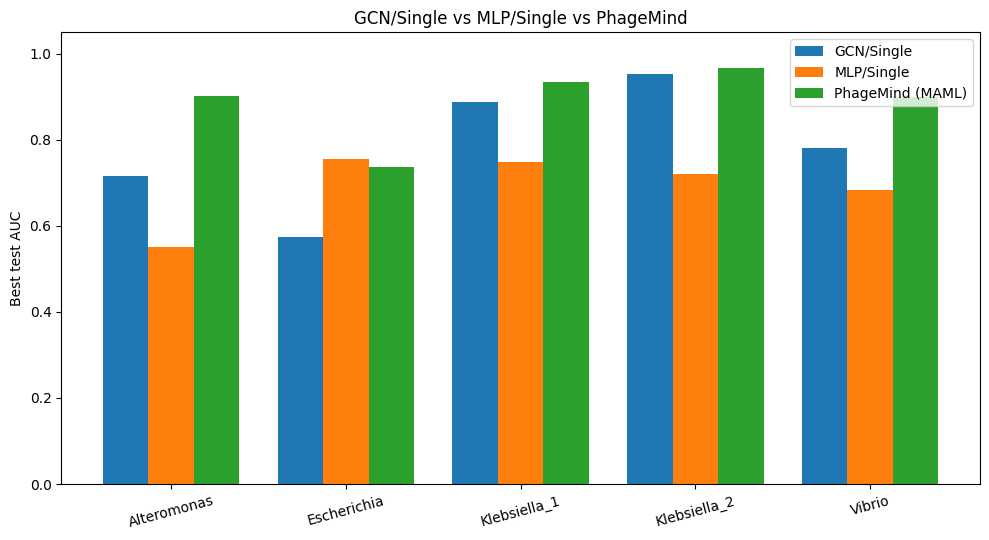

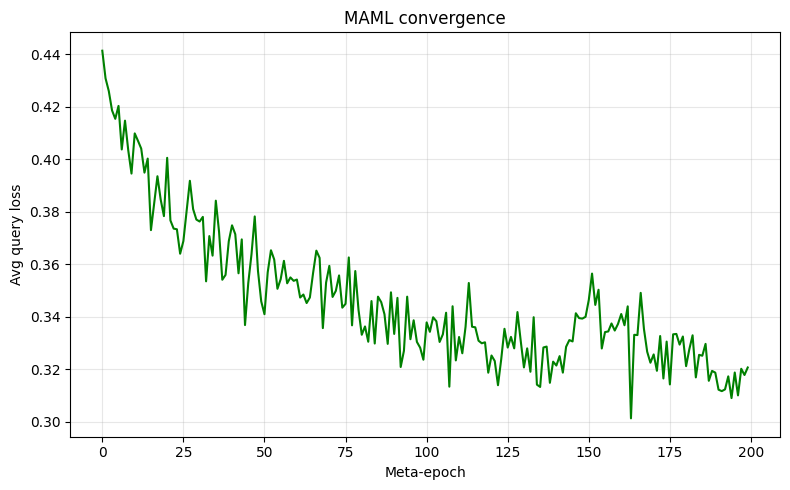

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

genera = list(phagemind_results.keys())
gcn_vals = [results[g]['gcn'] for g in genera]
mlp_vals = [results[g]['mlp'] for g in genera]
pm_vals = [phagemind_results[g] for g in genera]

x = np.arange(len(genera)); width = 0.26
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(x - width, gcn_vals, width, label='GCN/Single')
ax.bar(x, mlp_vals, width, label='MLP/Single')
ax.bar(x + width, pm_vals, width, label='PhageMind (MAML)')
ax.set_xticks(x); ax.set_xticklabels(genera, rotation=15)
ax.set_ylabel('Best test AUC'); ax.set_ylim(0, 1.05)
ax.legend(); ax.set_title('GCN/Single vs MLP/Single vs PhageMind')
plt.tight_layout(); plt.show()

plt.figure(figsize=(8,5))
plt.plot(range(0, len(meta_hist)*1, 1), [l for l in meta_hist if l is not None], color='green')
plt.xlabel('Meta-epoch'); plt.ylabel('Avg query loss'); plt.title('MAML convergence')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [ ]:
%%writefile /content/PhageMind_repo/src/phagemind_visualize.py

Overwriting /content/PhageMind_repo/src/phagemind_visualize.py


In [ ]:
import sys
for mod in list(sys.modules.keys()):
    if mod.startswith('phagemind'):
        del sys.modules[mod]


# per-genus loss/AUC/accuracy curves
for genus in genera:
    fig = plot_training_curves(finetune_histories[genus], title=f"PhageMind — {genus}")
    fig.show()

# bar chart, best test AUC per genus, all three variants (needs the accuracy-patched reruns)
per_genus = {g: {'GCN/Single': results[g]['gcn'], 'MLP/Single': results[g]['mlp'],
                  'PhageMind': phagemind_results[g]} for g in genera}
plot_multi_genus_bar(per_genus, metric_name='best test AUC', title='AUC comparison').show()

# t-SNE across all 5 genera using the meta-learned model, colored by node type + genus
fig = tsne_across_genera(meta_model, split_dir, genera, split='test', device=device,
                          title='Meta-learned embeddings across genera')
fig.show()

NameError: name 'plot_training_curves' is not defined